# Task 5 — Account Security Monitoring (Unsupervised Anomaly Detection)

**ทีม ML011 · CPE342 Machine Learning 1/2026**

**โจทย์:** มีข้อมูลผู้เล่น 25,889 account ไม่มี label ให้ ต้องหาว่า account ไหน *ผิดปกติ* (`is_anomaly` = 1) เช่น บัญชีถูกขโมย, bot, ใช้ VPN เลี่ยงราคา

**Metric: F3** = 10·P·R / (9P + R) → ให้น้ำหนัก **recall มากกว่า precision 9 เท่า** แปลว่า *พลาด anomaly 1 ตัวแย่กว่า flag คนปกติเกินมา* มาก

**แนวคิดหลักของ notebook นี้**

| ขั้น | ทำอะไร | เพราะอะไร (ดูหลักฐานใน section นั้น) |
|---|---|---|
| 1–2 | ตรวจ missing / noise / distribution ตามช่วงเวลา | ข้อมูลสกปรก ต้องเลือกวิธีที่ทนต่อ missing และ noise |
| 3–4 | temporal robust z → **anomaly แบบ A** | หาคนที่พฤติกรรม *เปลี่ยนกะทันหัน* ในช่วงหลัง เทียบกับตัวเอง |
| 5 | ระดับพฤติกรรมประจำตัว → **anomaly แบบ B** | คนที่ผิดปกติ *ตั้งแต่แรกและตลอดทุกช่วง* ไม่มี "การเปลี่ยน" ให้ temporal z เห็น |
| 6 | flags | ดูว่า flag ช่วยยืนยันแบบไหนได้บ้าง |
| 7 | Models: baseline vs score ของแต่ละแบบ → รวมกัน | ไม่มี model ตัวเดียวที่เห็นทั้งสองแบบ |
| 8 | ตรวจซ้ำด้วย PCA / HBOS / Mahalanobis / One-Class SVM / Autoencoder | ยืนยันแบบ A/B ด้วยวิธีมาตรฐาน และตรวจว่ายังมี anomaly เหลือนอกแบบ A/B ไหม |
| 9–10 | เลือก threshold แล้ว export | F3 → เผื่อ flag เกินเล็กน้อย |

**กัน data leakage:** ใช้เฉพาะ feature พฤติกรรม · ไม่ใช้ `player_id` / ลำดับแถวเป็น feature · ไม่ sort แถว (แถวที่ i = `ANS{i:05d}`) · ไม่ใช้ pretrained model / AutoML · การ fit unsupervised model บน test.csv คือสิ่งที่โจทย์ตั้งใจ (ไม่มี train set)

**วิธีรัน (Colab):** อัปโหลด `test.csv` ไปที่ `/content/` แล้ว Run all

In [ ]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
warnings.filterwarnings('ignore')
SEED = 42

# chart style: blue = normal / reference, orange = anomaly / flagged, gray = context
C_NORMAL, C_ANOM, C_MUTED, C_GRID = '#2a78d6', '#eb6834', '#898781', '#e1e0d9'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': C_GRID, 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#c3c2b7', 'axes.titlesize': 10, 'axes.titleweight': 'bold',
                     'font.size': 8.5, 'legend.frameon': False})

OUT_DIR = '/content'
df = pd.read_csv(os.path.join(OUT_DIR, 'test.csv'))   # อัปโหลด test.csv ไว้ที่ /content/ ก่อนรัน
X = df.drop(columns=['player_id'])   # id ไม่ถูกใช้เป็น feature (กัน leakage)
cols = list(X.columns)
PERIOD_COLS = [c for c in cols if c[-2:] in ('_1', '_2', '_3', '_4')]
GROUPS = sorted({c[:-2] for c in PERIOD_COLS}, key=lambda g: cols.index(g + '_1'))
FLAGS = ['password_changed', 'vpn_usage', 'suspicious_login_time', 'mass_item_sale']
N = len(X)
print('rows:', N, '| features:', X.shape[1], '| behavior groups:', len(GROUPS), 'x 4 periods | static:', X.shape[1] - len(PERIOD_COLS))

rows: 25889 | features: 122 | behavior groups: 29 x 4 periods | static: 6


## 1. Missing values

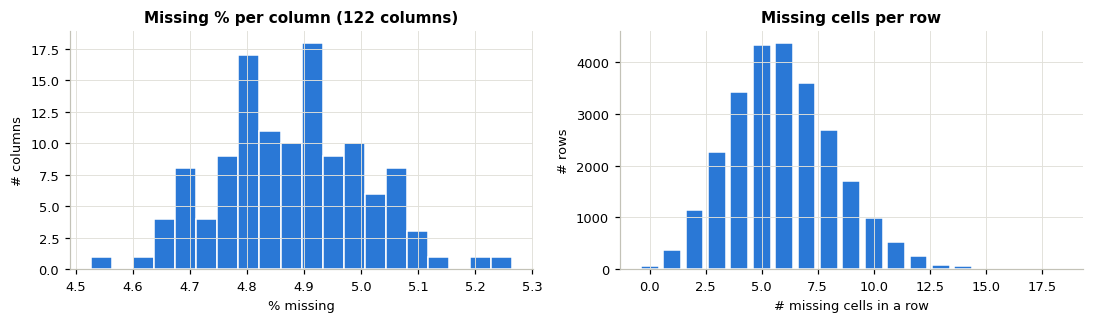

missing per column: 4.53% - 5.26%
rows with no missing at all: 59 of 25889
missing % by period: {1: 4.88, 2: 4.94, 3: 4.83, 4: 4.85}


In [ ]:
miss_col = X.isna().mean() * 100
miss_row = X.isna().sum(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(miss_col, bins=20, color=C_NORMAL, edgecolor='white')
ax[0].set(title='Missing % per column (122 columns)', xlabel='% missing', ylabel='# columns')
vc = miss_row.value_counts().sort_index()
ax[1].bar(vc.index, vc.values, color=C_NORMAL, edgecolor='white')
ax[1].set(title='Missing cells per row', xlabel='# missing cells in a row', ylabel='# rows')
plt.tight_layout(); plt.show()
print('missing per column: %.2f%% - %.2f%%' % (miss_col.min(), miss_col.max()))
print('rows with no missing at all: %d of %d' % ((miss_row == 0).sum(), N))
print('missing % by period:', {p: round(float(X[[g + '_' + str(p) for g in GROUPS]].isna().mean().mean()) * 100, 2) for p in range(1, 5)})

- **ดูอะไร:** สัดส่วนข้อมูลที่หายไป ต่อคอลัมน์ (ซ้าย) และต่อแถว (ขวา)
- **เห็นอะไร:** ทุกคอลัมน์หาย ≈ 5% เท่าๆ กัน ทุกช่วงเวลาเท่ากัน → หายแบบสุ่ม (ไม่ได้บอกอะไรเรื่อง anomaly) แต่เกือบทุกแถวมีช่องว่างอย่างน้อย 1 ช่อง
- **ผลต่องาน → ทำอะไร:** ลบแถวที่มี missing ไม่ได้ (จะเหลือไม่กี่สิบแถว) จึงต้องใช้วิธีที่ *ทนต่อ missing*: เวลาเทียบช่วงเวลา ใช้ `nanmedian` ของช่วงที่เหลือในแถวเดียวกัน และเติม median ให้ feature ที่ยังว่างก่อนเข้า model

## 2. Distribution ตามช่วงเวลา + noise

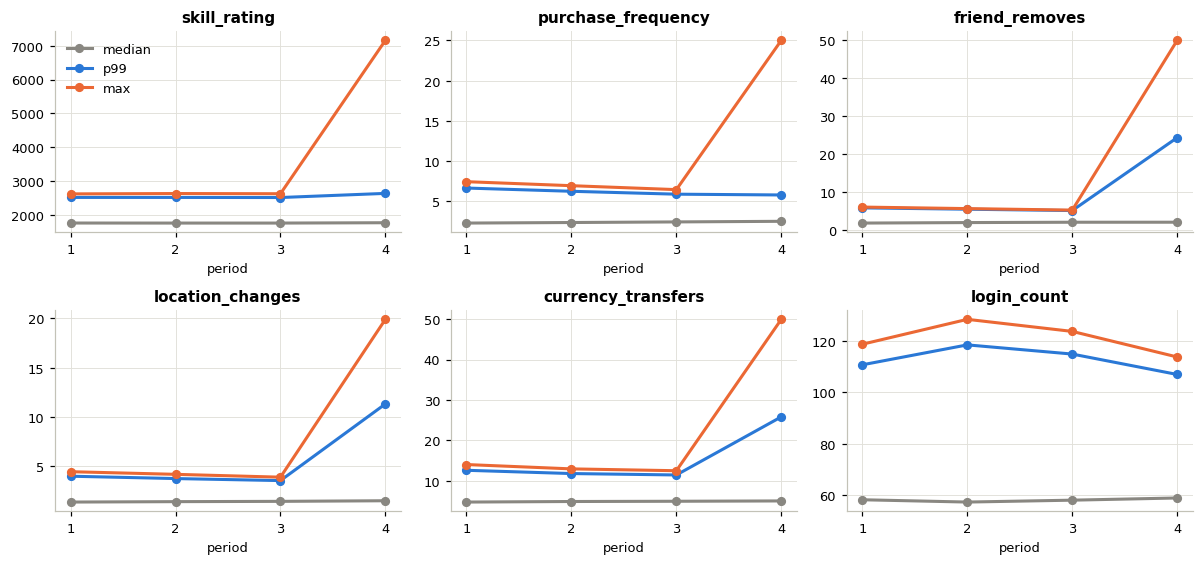

impossible / dirty values by period (count of rows):
                            p1    p2    p3   p4
refund_count < 0             0  4044  4141    0
guild_changes < 0            0  2698  2722    0
|login_lon| > 180           30    36    41  101
|login_lat| > 90             0     0     0   71
performance_stability > 1  351   327   151    0


In [ ]:
SHOW = ['skill_rating', 'purchase_frequency', 'friend_removes', 'location_changes', 'currency_transfers', 'login_count']
fig, axes = plt.subplots(2, 3, figsize=(11, 5.2))
for ax, g in zip(axes.ravel(), SHOW):
    vals = [X[g + '_' + str(p)].dropna() for p in range(1, 5)]
    for stat, color, lab in [(lambda v: v.median(), C_MUTED, 'median'), (lambda v: v.quantile(.99), C_NORMAL, 'p99'), (lambda v: v.max(), C_ANOM, 'max')]:
        ax.plot(range(1, 5), [stat(v) for v in vals], marker='o', ms=5, lw=2, color=color, label=lab)
    ax.set(title=g, xticks=[1, 2, 3, 4], xlabel='period')
axes[0, 0].legend()
plt.tight_layout(); plt.show()

print('impossible / dirty values by period (count of rows):')
noise = pd.DataFrame({'p%d' % p: {
    'refund_count < 0': int((X['refund_count_%d' % p] < 0).sum()),
    'guild_changes < 0': int((X['guild_changes_%d' % p] < 0).sum()),
    '|login_lon| > 180': int((X['login_lon_%d' % p].abs() > 180).sum()),
    '|login_lat| > 90': int((X['login_lat_%d' % p].abs() > 90).sum()),
    'performance_stability > 1': int((X['performance_stability_%d' % p] > 1).sum())} for p in range(1, 5)})
print(noise.to_string())

- **ดูอะไร:** ค่า median / p99 / max ของแต่ละพฤติกรรมในช่วงเวลา 1→4 (`login_count` คือตัวเทียบที่ไม่มีอะไรเกิด)
- **เห็นอะไร:** median ไม่ขยับเลย แต่ **max (และ p99 ในบางพฤติกรรม) พุ่งเฉพาะช่วง 4** (เช่น skill_rating ≈ 2,600 → ≈ 7,200, friend_removes ≈ 6 → ≈ 50) ส่วน `login_count` ไม่มีอะไรเกิด → มีคน *ส่วนน้อย* ที่พฤติกรรม *เปลี่ยนกะทันหันในช่วงหลัง* ซึ่งตรงกับเรื่อง account ถูกขโมย / bot
- ตาราง noise: refund/guild ติดลบมีเฉพาะช่วง 2–3 และ stability > 1 มีเฉพาะช่วง 1–3 (ไม่มีในช่วง 4 เลย) → เป็น noise ที่ใส่ไว้ ไม่ใช่สัญญาณ anomaly · ส่วนพิกัดเกินขอบเขตมีประปรายทุกช่วง แต่เพิ่มขึ้นในช่วง 4 = ปนกันระหว่าง noise กับ anomaly ที่ย้ายตำแหน่ง login
- **ผลต่องาน → ทำอะไร:** ถ้าป้อนค่าดิบให้ model มันจะสับสนระหว่าง *คนที่ค่าสูงมาตั้งแต่แรก* (ปกติ) กับ *คนที่เปลี่ยนกะทันหัน* (anomaly) และโดน noise หลอก → ต้องสร้าง feature ที่ **เทียบช่วงหลังกับช่วงก่อนของคนเดียวกัน** และใช้สถิติแบบ robust (median/MAD) ที่ไม่ไหวตาม noise

## 3. Feature engineering: temporal robust z

ต่อ account ต่อพฤติกรรม: `d = ค่าช่วง p − median(อีก 3 ช่วงของคนเดียวกัน)` แล้วแปลงเป็น robust z ข้ามทุก account (`(d − median) / (1.4826·MAD)`) → |z| สูง = คนนี้เปลี่ยนไปจากตัวเองมากเมื่อเทียบกับที่คนทั่วไปเปลี่ยน

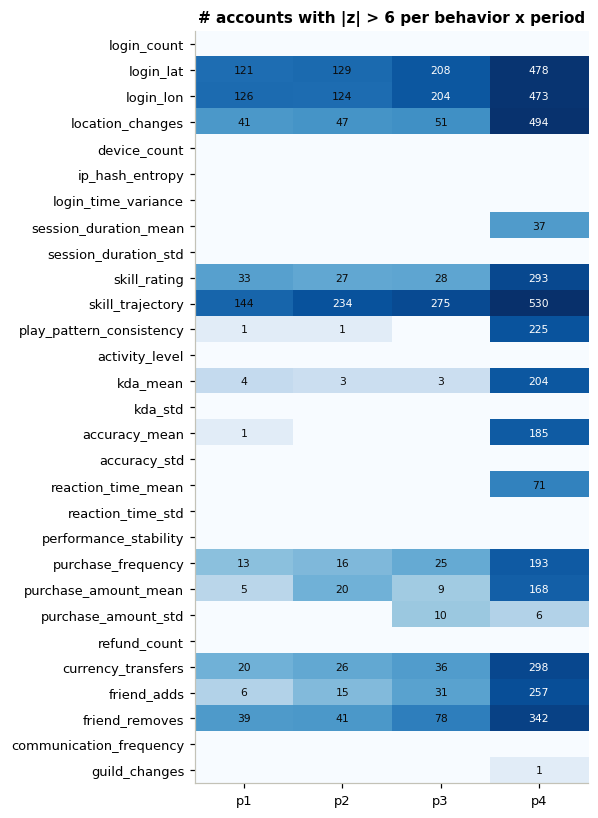

anomaly-prone groups (15): ['login_lat', 'login_lon', 'location_changes', 'session_duration_mean', 'skill_rating', 'skill_trajectory', 'play_pattern_consistency', 'kda_mean', 'accuracy_mean', 'reaction_time_mean', 'purchase_frequency', 'purchase_amount_mean', 'currency_transfers', 'friend_adds', 'friend_removes']
never-injected groups (14): ['login_count', 'device_count', 'ip_hash_entropy', 'login_time_variance', 'session_duration_std', 'activity_level', 'kda_std', 'accuracy_std', 'reaction_time_std', 'performance_stability', 'purchase_amount_std', 'refund_count', 'communication_frequency', 'guild_changes']


In [ ]:
def robust_z(d):
    med = np.nanmedian(d)
    mad = np.nanmedian(np.abs(d - med)) * 1.4826
    if not np.isfinite(mad) or mad == 0:
        mad = np.nanstd(d)
    if not np.isfinite(mad) or mad == 0:
        mad = 1.0
    return (d - med) / mad

# Z[p][:, j] = |robust z| ของ (ช่วง p - median ของอีก 3 ช่วง ในแถวเดียวกัน) สำหรับกลุ่ม j
Z = {}
for p in range(1, 5):
    zs = []
    for g in GROUPS:
        v = X[[g + '_' + str(q) for q in range(1, 5)]].to_numpy()
        d = v[:, p - 1] - np.nanmedian(np.delete(v, p - 1, axis=1), axis=1)
        zs.append(np.abs(np.nan_to_num(robust_z(d))))
    Z[p] = np.column_stack(zs)

def n_ext(p, T, gidx=None):
    z = Z[p] if gidx is None else Z[p][:, gidx]
    return (z > T).sum(axis=1)

cnt6 = pd.DataFrame({'p%d' % p: (Z[p] > 6).sum(axis=0) for p in range(1, 5)}, index=GROUPS)
fig, ax = plt.subplots(figsize=(5.5, 7.5))
ax.imshow(np.log10(cnt6.values + 1), cmap='Blues', aspect='auto')
ax.set(xticks=range(4), xticklabels=['p1', 'p2', 'p3', 'p4'], yticks=range(len(GROUPS)), yticklabels=GROUPS,
       title='# accounts with |z| > 6 per behavior x period')
ax.grid(False)
for i in range(len(GROUPS)):
    for j in range(4):
        v = int(cnt6.values[i, j])
        if v:
            ax.text(j, i, str(v), ha='center', va='center', fontsize=7, color='white' if v > 150 else '#0b0b0b')
plt.tight_layout(); plt.show()

base = cnt6[['p1', 'p2']].max(axis=1).clip(lower=1)
ANOM_G = [g for g in GROUPS if cnt6.loc[g, 'p4'] >= 30 and cnt6.loc[g, 'p4'] >= 2 * base[g]]
AG = [GROUPS.index(g) for g in ANOM_G]
OG = [i for i in range(len(GROUPS)) if i not in AG]
print('anomaly-prone groups (%d):' % len(ANOM_G), ANOM_G)
print('never-injected groups (%d):' % len(OG), [GROUPS[i] for i in OG])

- **ดูอะไร:** จำนวน account ที่เปลี่ยนแรงมาก (|z| > 6) แยกตามพฤติกรรม × ช่วงเวลา
- **เห็นอะไร:** ใน ≈ 15 พฤติกรรม (พิกัด login, location_changes, skill, friend, currency, purchase …) ช่อง p4 มีจำนวนมากกว่า p1–p3 หลายเท่า (เช่น location_changes 41–51 → 494, play_pattern_consistency 1 → 225) · บางพฤติกรรม (พิกัด login, skill_trajectory) มีค่าโดดทุกช่วงอยู่แล้ว = noise พื้นฐาน · อีก ≈ 14 พฤติกรรมว่างหรือแทบว่างทุกช่วง (login_count, device_count, *_std …)
- **ผลต่องาน → ทำอะไร:** anomaly ถูกฝังไว้ใน *ช่วง 4 (บางส่วนช่วง 3) ของบางพฤติกรรมเท่านั้น* → (1) ใช้ |z| ของช่วง 3/4 เป็น feature หลัก (2) แยกชุด **anomaly-prone groups** ไว้ทำ model ที่ไม่ถูกกลุ่มที่มีแต่ noise ดึงความสนใจ

## 4. Anomaly แบบ A: เปลี่ยนพฤติกรรมกะทันหันในช่วงหลัง

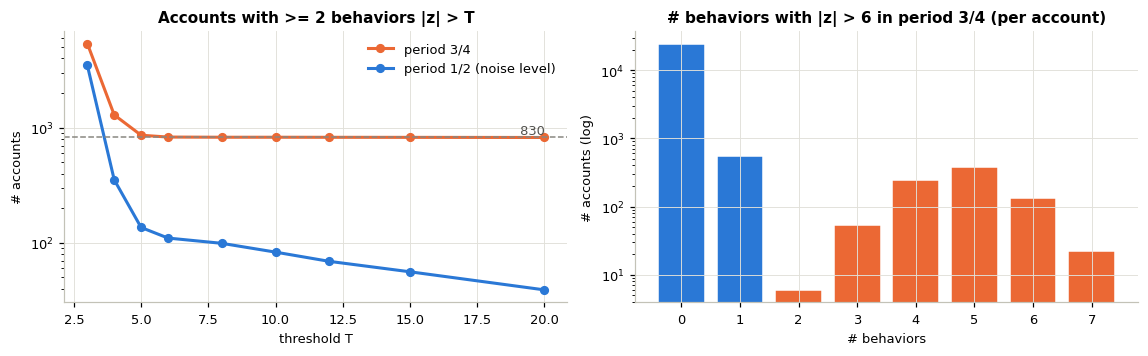

T     : [3, 4, 5, 6, 8, 10, 12, 15, 20]
p3/p4 : [5393, 1293, 861, 830, 827, 827, 826, 825, 823]
p1/p2 : [3492, 353, 136, 110, 99, 83, 69, 56, 39]
type A (>= 2 behaviors |z| > 6 in p3/p4): 830 accounts (3.21%)


In [ ]:
Ts = [3, 4, 5, 6, 8, 10, 12, 15, 20]
def rows_ge2(T, periods):
    return int((np.max([n_ext(p, T) for p in periods], axis=0) >= 2).sum())
late = [rows_ge2(T, (3, 4)) for T in Ts]
early = [rows_ge2(T, (1, 2)) for T in Ts]

next34 = np.maximum(n_ext(3, 6), n_ext(4, 6))
sus = next34 >= 2          # anomaly แบบ A
n_sus = int(sus.sum())

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.3))
ax[0].plot(Ts, late, marker='o', ms=5, lw=2, color=C_ANOM, label='period 3/4')
ax[0].plot(Ts, early, marker='o', ms=5, lw=2, color=C_NORMAL, label='period 1/2 (noise level)')
ax[0].axhline(n_sus, color=C_MUTED, lw=1, ls='--')
ax[0].text(20, n_sus, ' %d' % n_sus, va='bottom', ha='right', color='#52514e')
ax[0].set(title='Accounts with >= 2 behaviors |z| > T', xlabel='threshold T', ylabel='# accounts', yscale='log')
ax[0].legend()
vc = pd.Series(next34).value_counts().sort_index()
ax[1].bar(vc.index, vc.values, color=[C_NORMAL if k < 2 else C_ANOM for k in vc.index], edgecolor='white')
ax[1].set(title='# behaviors with |z| > 6 in period 3/4 (per account)', xlabel='# behaviors', ylabel='# accounts (log)', yscale='log')
plt.tight_layout(); plt.show()
print('T     :', Ts)
print('p3/p4 :', late)
print('p1/p2 :', early)
print('type A (>= 2 behaviors |z| > 6 in p3/p4): %d accounts (%.2f%%)' % (n_sus, n_sus / N * 100))

- **ดูอะไร:** ถ้าตั้งเกณฑ์ว่า "เปลี่ยนแรงเกิน T พร้อมกันอย่างน้อย 2 พฤติกรรม" จะได้กี่ account เมื่อเลื่อน T (ซ้าย) และ account หนึ่งเปลี่ยนแรงพร้อมกันกี่พฤติกรรม (ขวา)
- **เห็นอะไร:** เส้นช่วง 3/4 **แทบราบตั้งแต่ T = 6 ถึง 20** (830 → 823: เพิ่มเกณฑ์ขึ้นกว่า 3 เท่าหายไปแค่ 7 คน = ยังเป็นคนกลุ่มเดิม) ขณะที่เส้นช่วง 1/2 ลดลงเรื่อยๆ ตาม T แบบ noise ทั่วไป · กราฟขวา: แทบไม่มีใครอยู่ที่ 2 พฤติกรรม แต่มีกองแยกที่ 3–7 พฤติกรรม → มีกลุ่มคน 3.2% ที่เปลี่ยนแรงมาก *หลายพฤติกรรมพร้อมกัน* แยกจากคนอื่นแบบมีช่องว่างชัด ส่วน T < 6 ตัวเลขพุ่งเพราะ noise
- **ผลต่องาน → ทำอะไร:** เรียกกลุ่มนี้ว่า **anomaly แบบ A** (ตัวแปร `sus`) · แต่ temporal z วัดแค่ *การเปลี่ยน* — ถ้ามี account ที่ผิดปกติมาตั้งแต่ช่วงแรกและคงที่ทุกช่วง วิธีนี้จะมองไม่เห็นเลย → section ถัดไปดูอีกมุมหนึ่ง

## 5. Anomaly แบบ B: พฤติกรรมผิดปกติตั้งแต่แรก

ใช้ *ระดับพฤติกรรมประจำตัว* ของแต่ละ account = median ของ 4 ช่วง (ทนต่อ missing และค่าโดดช่วงเดียว) แล้วหา **ช่องว่างใน histogram** (bin ว่างติดกัน) ที่แบ่งคนกลุ่มเล็ก (≤ 10%) ออกจากคนส่วนใหญ่ · ข้ามตัวแปรนับจำนวนเต็มเพราะ histogram ของมันมีช่องว่างอยู่แล้วตามธรรมชาติ

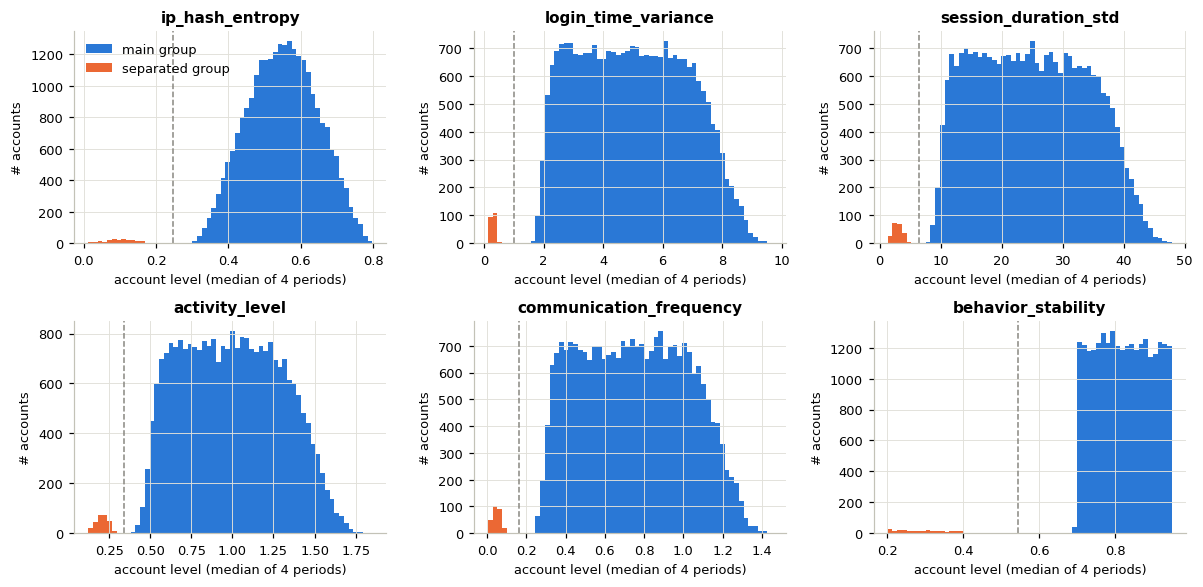

ip_hash_entropy          < 0.248 :  207 accounts
login_time_variance      < 1.01 :  207 accounts
session_duration_std     < 6.4 :  207 accounts
activity_level           < 0.338 :  265 accounts
communication_frequency  < 0.162 :  263 accounts
behavior_stability       < 0.544 :  246 accounts

# accounts in both groups (diagonal = group size):
                           B:ip_hash_entropy  B:activity_level  B:communication_frequency  B:behavior_stability  A:temporal
B:ip_hash_entropy                        207                 0                          0                     0           0
B:activity_level                           0               265                          0                     0           0
B:communication_frequency                  0                 0                        263                     0           0
B:behavior_stability                       0                 0                          0                   246           0
A:temporal                           

In [ ]:
# ระดับพฤติกรรมประจำตัวของแต่ละ account = median ของ 4 ช่วง (ทนต่อ missing และค่าโดดช่วงเดียว)
LV = pd.DataFrame({g: X[[g + '_' + str(p) for p in range(1, 5)]].median(axis=1) for g in GROUPS})
LV['behavior_stability'] = X['behavior_stability']
LV['account_age_days'] = X['account_age_days']

def gap_split(v, bins=60, min_gap=2, max_share=0.10):
    # หา 'ช่องว่าง' ใน histogram (bin ว่างติดกัน >= min_gap) แล้วคืนฝั่งที่เป็นกลุ่มเล็ก (<= 10% ของ account)
    h, e = np.histogram(v.dropna(), bins=bins)
    i = 0
    while i < bins:
        if h[i] == 0:
            j = i
            while j < bins and h[j] == 0:
                j += 1
            if j - i >= min_gap and 0 < i and j < bins:
                cut = (e[i] + e[j]) / 2
                for side, m in (('<', v < cut), ('>', v > cut)):
                    if 0 < m.mean() <= max_share:
                        return m.to_numpy(), side, cut
            i = j
        else:
            i += 1
    return None

CONT = [c for c in LV.columns if LV[c].nunique() > 50]   # ข้ามตัวแปรนับจำนวนเต็ม (histogram มีช่องว่างตามธรรมชาติ)
found = {c: r for c in CONT if (r := gap_split(LV[c])) is not None and r[0].sum() >= 30}

# feature ที่ชี้ไปที่ account ชุดเดียวกัน = กลุ่มเดียวกัน
B = {}
for c, (m, side, cut) in found.items():
    k = next((k for k, g in B.items() if (g['mask'] & m).sum() >= 0.9 * m.sum()), None)
    if k is None:
        B[c] = {'mask': m, 'feats': [c]}
    else:
        B[k]['feats'].append(c)
typeB = np.zeros(N, bool)
for g in B.values():
    typeB |= g['mask']

nr = int(np.ceil(len(found) / 3))
fig, axes = plt.subplots(nr, 3, figsize=(11, 2.7 * nr))
for ax, (c, (m, side, cut)) in zip(axes.ravel(), found.items()):
    ok = LV[c].notna().to_numpy(); v = LV[c].to_numpy()
    bins = np.linspace(np.nanmin(v), np.nanmax(v), 61)
    ax.hist(v[ok & ~m], bins=bins, color=C_NORMAL, label='main group')
    ax.hist(v[ok & m], bins=bins, color=C_ANOM, label='separated group')
    ax.axvline(cut, color=C_MUTED, ls='--', lw=1)
    ax.set(title=c, xlabel='account level (median of 4 periods)', ylabel='# accounts')
axes.ravel()[0].legend()
for ax in axes.ravel()[len(found):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

for c, (m, side, cut) in found.items():
    print('%-24s %s %.3g : %4d accounts' % (c, side, cut, m.sum()))
M = pd.DataFrame({**{'B:' + g['feats'][0]: g['mask'] for g in B.values()}, 'A:temporal': sus}).astype(int)
print('\n# accounts in both groups (diagonal = group size):')
print((M.T @ M).to_string())
print('\ntype A = %d | type B = %d | A or B = %d (%.2f%%)' % (sus.sum(), typeB.sum(), (sus | typeB).sum(), (sus | typeB).mean() * 100))

- **ดูอะไร:** histogram ของระดับพฤติกรรมที่เจอช่องว่าง (ส้ม = กลุ่มที่แยกออกมา, เส้นประ = จุดแบ่ง) และตารางว่าแต่ละกลุ่มซ้อนกันไหม
- **เห็นอะไร:** เจอ 6 feature ที่มีกลุ่มเล็กแยกออกมาทางฝั่งค่าต่ำแบบมีช่องว่างชัด และรวมได้เป็น **4 กลุ่มที่ไม่ซ้อนกันเลย และไม่ซ้อนกับแบบ A**
  - `ip_hash_entropy` + `login_time_variance` + `session_duration_std` ต่ำพร้อมกัน (207 account ชุดเดียวกันทั้ง 3 feature) = IP เดิม เข้าเวลาเดิม เล่นนานเท่าเดิมทุกครั้ง → ลักษณะ **bot**
  - `activity_level` ต่ำผิดปกติ (265) · `communication_frequency` ต่ำผิดปกติ (263) · `behavior_stability` ต่ำผิดปกติ (246)
  - รวมแบบ B = 981 account · แบบ A + B = 1,811 account (7.0%)
- **ผลต่องาน → ทำอะไร:** anomaly ในข้อมูลนี้มีอย่างน้อย 2 แบบที่ต้องใช้คนละมุมมอง → model สุดท้ายต้องมี score สำหรับทั้งสองแบบ ไม่ใช่แค่ temporal z อย่างเดียว

## 6. Flags: แต่ละกลุ่มเกี่ยวกับ flag แค่ไหน

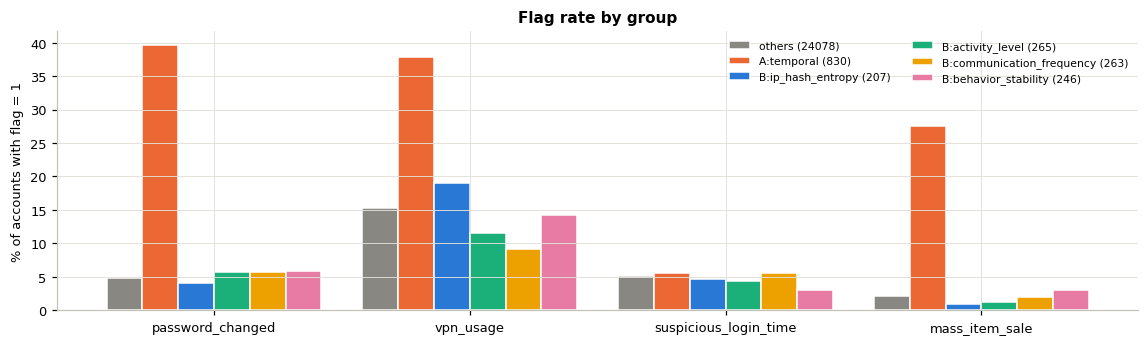

                       others  A:temporal  B:ip_hash_entropy  B:activity_level  B:communication_frequency  B:behavior_stability
password_changed          4.9        39.7                4.1               5.7                        5.7                   5.9
vpn_usage                15.3        37.8               19.0              11.6                        9.1                  14.2
suspicious_login_time     5.1         5.6                4.6               4.4                        5.5                   3.0
mass_item_sale            2.1        27.6                1.0               1.2                        2.0                   3.0


In [ ]:
grp = {'others': ~(sus | typeB), 'A:temporal': sus}
grp.update({'B:' + g['feats'][0]: g['mask'] for g in B.values()})
rate = pd.DataFrame({k: X.loc[m, FLAGS].mean() * 100 for k, m in grp.items()})
PAL = ['#898781', '#eb6834', '#2a78d6', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
fig, ax = plt.subplots(figsize=(10.5, 3.2))
xs = np.arange(len(FLAGS)); w = 0.84 / len(grp)
for i, k in enumerate(rate.columns):
    ax.bar(xs + (i - (len(grp) - 1) / 2) * w, rate[k].values, w, color=PAL[i % len(PAL)], label='%s (%d)' % (k, grp[k].sum()), edgecolor='white')
ax.set(xticks=xs, xticklabels=FLAGS, ylabel='% of accounts with flag = 1', title='Flag rate by group')
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
print(rate.round(1).to_string())

- **ดูอะไร:** สัดส่วน account ที่มี flag = 1 (ระบบเดิมตรวจได้) แยกตามกลุ่ม
- **เห็นอะไร:** แบบ A มี `password_changed` (40%) และ `mass_item_sale` (28%) สูงกว่าคนทั่วไปหลายเท่า (5% และ 2%) และ `vpn_usage` สูงกว่า ≈ 2.5 เท่า (38% vs 15%) → เข้ากับเรื่อง account ถูกขโมย (เปลี่ยนรหัส → ขายของ) · แต่ทุกกลุ่มของแบบ B มี flag พอๆ กับคนทั่วไป · `suspicious_login_time` ไม่ต่างในทุกกลุ่ม
- **ผลต่องาน → ทำอะไร:** flag เป็นหลักฐานอิสระที่ยืนยันว่าแบบ A ผิดปกติจริง จึงใส่เป็น feature เสริมใน score ของแบบ A · แต่ **ใช้ flag หาแบบ B ไม่ได้** ระบบที่ดูแค่ flag จะพลาดกลุ่ม bot และกลุ่มอื่นทั้งหมด

## 7. Models

| score | input | บทบาท |
|---|---|---|
| `IF raw` (baseline ของโจทย์) | ค่าดิบ 122 คอลัมน์ | ไว้เทียบ |
| `IF on levels` | ระดับพฤติกรรมประจำตัว (standardized) | ไว้เทียบ: IF แบบตรงๆ บนมุมมองแบบ B |
| **type A score** | rank average ของ IF บน \|z\| ช่วง 3/4 + ระยะทาง login + flags, IF เฉพาะพฤติกรรมที่ถูกฝัง และ Σ log(1+\|z\|) | หาแบบ A |
| **type B score** | ความลึกในหางฝั่งกลุ่มเล็ก (percentile) ของ feature ที่มีช่องว่าง | หาแบบ B |
| **final** | account ในกลุ่มที่แยกชัด (A หรือ B) อยู่บนสุด ที่เหลือเรียงตาม max(rank type A, type B score) | score สุดท้าย |

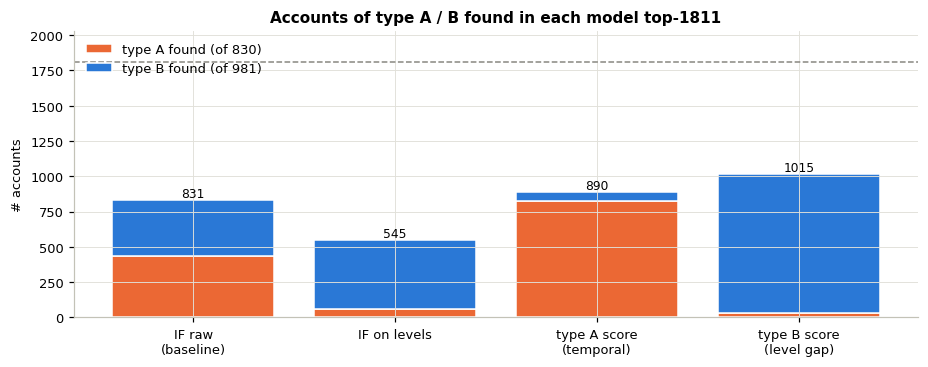

top-1811 of each model:
  IF raw (baseline)          type A  435 / 830 | type B  396 / 981
  IF on levels               type A   62 / 830 | type B  483 / 981
  type A score (temporal)    type A  827 / 830 | type B   63 / 981
  type B score (level gap)   type A   34 / 830 | type B  981 / 981


In [ ]:
def hav(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def topk(score, k):
    m = np.zeros(N, bool)
    m[np.argsort(-np.asarray(score), kind='stable')[:k]] = True
    return m

def iforest(F):
    return -IsolationForest(n_estimators=500, random_state=SEED, n_jobs=-1).fit(F).score_samples(F)

KM = pd.DataFrame({'km_%d_%d' % (p - 1, p): hav(X['login_lat_%d' % (p - 1)], X['login_lon_%d' % (p - 1)], X['login_lat_%d' % p], X['login_lon_%d' % p]) for p in (2, 3, 4)})
KM = KM.fillna(KM.median())

# baseline ของโจทย์: IF บนค่าดิบ
s_raw = iforest(X.fillna(X.median()))
# IF บนระดับพฤติกรรม (เทียบ)
LVz = LV.fillna(LV.median()); LVz = (LVz - LVz.median()) / LVz.std()
s_lvl = iforest(LVz)
# score type A: ensemble ของการเปลี่ยนตามเวลา (IF 2 ตัว + zsum, rank average)
F_eng = pd.concat([pd.DataFrame(np.hstack([Z[3], Z[4]])), KM, X[FLAGS].fillna(0)], axis=1)
F_eng.columns = [str(c) for c in F_eng.columns]
F_prone = pd.concat([pd.DataFrame(np.hstack([Z[3][:, AG], Z[4][:, AG]])), KM[['km_2_3', 'km_3_4']]], axis=1)
F_prone.columns = [str(c) for c in F_prone.columns]
s_zsum = np.log1p(np.maximum(Z[3][:, AG], Z[4][:, AG])).sum(axis=1)
s_A = pd.DataFrame({'IF eng': iforest(F_eng), 'IF prone': iforest(F_prone), 'zsum': s_zsum}).rank(pct=True).mean(axis=1).to_numpy()
# score type B: อยู่ลึกแค่ไหนในหางฝั่งกลุ่มเล็ก ของ feature ที่มีช่องว่าง (percentile)
s_B = np.zeros(N)
for c, (m, side, cut) in found.items():
    r = LV[c].rank(pct=True).fillna(0.5).to_numpy()
    s_B = np.maximum(s_B, 1 - r if side == '<' else r)
# final: account ในกลุ่มที่แยกชัด (A หรือ B) อยู่บนสุด ที่เหลือเรียงตาม score ที่สูงกว่าระหว่าง A กับ B
AB = sus | typeB
final = np.maximum(pd.Series(s_A).rank(pct=True).to_numpy(), s_B) + AB

n_ab = int(AB.sum())
models = {'IF raw\n(baseline)': s_raw, 'IF on levels': s_lvl, 'type A score\n(temporal)': s_A, 'type B score\n(level gap)': s_B}
fA = {k: int((topk(v, n_ab) & sus).sum()) for k, v in models.items()}
fB = {k: int((topk(v, n_ab) & typeB).sum()) for k, v in models.items()}
fig, ax = plt.subplots(figsize=(8.5, 3.4))
names = list(models)
ax.bar(names, [fA[k] for k in names], color=C_ANOM, label='type A found (of %d)' % sus.sum(), edgecolor='white')
ax.bar(names, [fB[k] for k in names], bottom=[fA[k] for k in names], color=C_NORMAL, label='type B found (of %d)' % typeB.sum(), edgecolor='white')
for i, k in enumerate(names):
    ax.text(i, fA[k] + fB[k], '%d' % (fA[k] + fB[k]), ha='center', va='bottom', fontsize=8)
ax.axhline(n_ab, color=C_MUTED, ls='--', lw=1)
ax.set(title='Accounts of type A / B found in each model top-%d' % n_ab, ylabel='# accounts', ylim=(0, n_ab * 1.12))
ax.legend(loc='upper left'); plt.tight_layout(); plt.show()
print('top-%d of each model:' % n_ab)
for k in names:
    print('  %-26s type A %4d / %d | type B %4d / %d' % (k.replace(chr(10), ' '), fA[k], sus.sum(), fB[k], typeB.sum()))

- **ดูอะไร:** ถ้าให้แต่ละ score เลือก 1,811 account ที่น่าสงสัยที่สุด (= ขนาดแบบ A + B) จะเจอแบบ A (ส้ม) และแบบ B (ฟ้า) กี่คน
- **เห็นอะไร:** `IF raw` แบบ baseline เจอรวม 831 คน (A 435, B 396) เพราะค่าดิบปนทั้ง noise และความต่างระหว่างคน · `IF on levels` เจอแค่ 545 เพราะมี 31 มิติที่กระจายสม่ำเสมอ ทำให้กลุ่มเล็กที่ผิดปกติแค่ 1–3 มิติถูกกลบ · type A score เจอแบบ A 827 / 830 แต่เจอแบบ B แค่ 63 · type B score เจอแบบ B ครบ 981 แต่เจอแบบ A แค่ 34
- **ผลต่องาน → ทำอะไร:** แต่ละ score เก่งคนละแบบและแทบไม่ซ้อนกัน → **final ต้องรวมทั้งสอง** (เอาอันที่สูงกว่า) ไม่ใช่เฉลี่ย เพราะการเฉลี่ยจะดึง account ที่สูงแค่ด้านเดียวลงมา · สิ่งที่ทำให้ดีกว่า baseline คือ feature engineering ที่ตรงกับลักษณะของแต่ละแบบ ไม่ใช่การเปลี่ยน algorithm

## 8. ตรวจซ้ำด้วยวิธี anomaly detection มาตรฐาน

ใช้วิธีมาตรฐานที่ไม่ได้ออกแบบมาเฉพาะข้อมูลชุดนี้มาตรวจคำถาม 3 ข้อ (ไม่มีวิธีไหนใช้ `player_id` / ลำดับแถว และทุกวิธีเป็น unsupervised ที่ fit บนข้อมูลพฤติกรรมเท่านั้น)

| ส่วน | วิธี | คำถาม |
|---|---|---|
| 8.1 | **PCA latent-variable model**: fit บนช่วง 1–2 (ช่วงอ้างอิง) แล้ววัด reconstruction error (MAE) และ Hotelling T² (= Mahalanobis² ใน PC space, เทียบ χ²) ของแต่ละช่วง | การเปลี่ยนแปลงในช่วงหลังที่ PCA เห็น ตรงกับแบบ A หรือมีคนกลุ่มใหม่ (เช่น เปลี่ยนหลายพฤติกรรมพร้อมกันแบบอ่อนๆ) |
| 8.2 | **HBOS, Mahalanobis distance, One-Class SVM, Autoencoder** บนระดับพฤติกรรมประจำตัว | วิธีมาตรฐานเห็นแบบ B ได้แค่ไหน เทียบกับ type B score |
| 8.3 | account ที่ไม่อยู่ในแบบ A/B: เทียบจำนวนที่เกินเกณฑ์ตามช่วงเวลา + Mahalanobis² เทียบ χ² | ยังมี anomaly ซ่อนอยู่นอกแบบ A/B หรือไม่ (มีผลต่อการเลือก threshold)

### 8.1 PCA latent-variable model: fit บนช่วง 1–2 แล้วตรวจช่วง 3–4

skewness of 29 behaviors (period 1-2): min -0.16 | max 0.50 -> behaviors with |skew| > 1: []


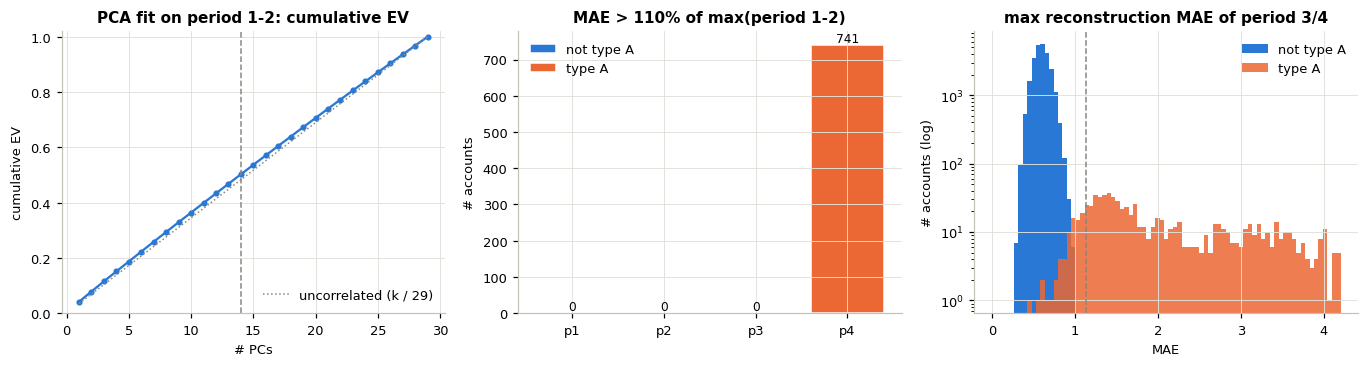

PCs: 14 (EV 0.50) | THR_MAE = 1.134 | THR_T2 = chi2(14, 0.999) = 36.1
                    p1   p2   p3   p4
MAE > thr: type A    0    0    0  741
MAE > thr: others    0    0    0    0
T2 > chi2: type A    0    0    0  821
T2 > chi2: type B  118  130  128  115
T2 > chi2: others    8    5    2    0
PCA flag (MAE p3 or p4 > thr): 741 accounts | type A 741 / 830 | not type A 0


In [ ]:
from scipy import stats
from sklearn.decomposition import PCA

# แต่ละ account ในแต่ละช่วง = เวกเตอร์ 29 พฤติกรรม · ช่วง 1-2 = ช่วงอ้างอิง (ยังไม่มีการเปลี่ยนแปลง) แบบเดียวกับ train data ใน lab
PER = {p: pd.DataFrame(X[[g + '_' + str(p) for g in GROUPS]].to_numpy(float), columns=GROUPS) for p in range(1, 5)}
REF = pd.concat([PER[1], PER[2]])
skew = REF.skew()
print('skewness of 29 behaviors (period 1-2): min %.2f | max %.2f -> behaviors with |skew| > 1: %s' % (skew.min(), skew.max(), [g for g in GROUPS if abs(skew[g]) > 1]))
ref_med = REF.median(); ref_mu = REF.fillna(ref_med).mean(); ref_sd = REF.fillna(ref_med).std()
S = {p: ((PER[p].fillna(ref_med) - ref_mu) / ref_sd).to_numpy() for p in range(1, 5)}   # standardize ด้วยค่าจากช่วงอ้างอิง
S_ref = np.vstack([S[1], S[2]])

cev = np.cumsum(PCA().fit(S_ref).explained_variance_ratio_)
K_PC = int(np.searchsorted(cev, 0.5) + 1)            # จำนวน PC ที่อธิบาย variance >= 50%
pca = PCA(n_components=K_PC, random_state=SEED).fit(S_ref)
MAE, T2 = {}, {}
for p in range(1, 5):
    pc = pca.transform(S[p])
    MAE[p] = np.abs(S[p] - pca.inverse_transform(pc)).mean(axis=1)   # reconstruction error
    T2[p] = (pc ** 2 / pca.explained_variance_).sum(axis=1)          # MHD^2 ใน PC space
THR_MAE = 1.10 * np.concatenate([MAE[1], MAE[2]]).max()   # 110% ของ error สูงสุดในช่วงอ้างอิง (แบบ lab)
THR_T2 = stats.chi2.ppf(1 - 0.001, K_PC)                  # MHD^2 ~ chi2(k), alpha = 0.001
pca_flag = (MAE[3] > THR_MAE) | (MAE[4] > THR_MAE)

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].plot(range(1, len(cev) + 1), cev, marker='o', ms=3, lw=1.5, color=C_NORMAL)
ax[0].plot(range(1, len(cev) + 1), np.arange(1, len(cev) + 1) / len(cev), lw=1, ls=':', color=C_MUTED, label='uncorrelated (k / 29)')
ax[0].axvline(K_PC, color=C_MUTED, ls='--', lw=1)
ax[0].set(title='PCA fit on period 1-2: cumulative EV', xlabel='# PCs', ylabel='cumulative EV', ylim=(0, 1.02))
ax[0].legend(loc='lower right')
xs = np.arange(1, 5)
cA = [int((sus & (MAE[p] > THR_MAE)).sum()) for p in xs]
cO = [int((~sus & (MAE[p] > THR_MAE)).sum()) for p in xs]
ax[1].bar(xs, cO, color=C_NORMAL, edgecolor='white', label='not type A')
ax[1].bar(xs, cA, bottom=cO, color=C_ANOM, edgecolor='white', label='type A')
for x, a, o in zip(xs, cA, cO):
    ax[1].text(x, a + o, str(a + o), ha='center', va='bottom', fontsize=8)
ax[1].set(title='MAE > 110% of max(period 1-2)', xticks=xs, xticklabels=['p1', 'p2', 'p3', 'p4'], ylabel='# accounts')
ax[1].legend(loc='upper left')
m34 = np.maximum(MAE[3], MAE[4])
bins = np.linspace(0, np.quantile(m34, 0.9995), 80)
ax[2].hist(m34[~sus], bins=bins, color=C_NORMAL, label='not type A')
ax[2].hist(m34[sus], bins=bins, color=C_ANOM, alpha=0.85, label='type A')
ax[2].axvline(THR_MAE, color=C_MUTED, ls='--', lw=1)
ax[2].set(title='max reconstruction MAE of period 3/4', xlabel='MAE', ylabel='# accounts (log)', yscale='log')
ax[2].legend()
plt.tight_layout(); plt.show()

print('PCs: %d (EV %.2f) | THR_MAE = %.3f | THR_T2 = chi2(%d, 0.999) = %.1f' % (K_PC, cev[K_PC - 1], THR_MAE, K_PC, THR_T2))
tab = pd.DataFrame({'p%d' % p: {'MAE > thr: type A': int((sus & (MAE[p] > THR_MAE)).sum()), 'MAE > thr: others': int((~sus & (MAE[p] > THR_MAE)).sum()),
                                'T2 > chi2: type A': int((sus & (T2[p] > THR_T2)).sum()), 'T2 > chi2: type B': int((typeB & (T2[p] > THR_T2)).sum()),
                                'T2 > chi2: others': int((~AB & (T2[p] > THR_T2)).sum())} for p in range(1, 5)})
print(tab.to_string())
print('PCA flag (MAE p3 or p4 > thr): %d accounts | type A %d / %d | not type A %d' % (pca_flag.sum(), (pca_flag & sus).sum(), sus.sum(), (pca_flag & ~sus).sum()))

- **ดูอะไร:** (ซ้าย) PCA ที่ fit บนช่วง 1–2 ต้องใช้กี่ PC จึงอธิบาย variance ได้ · (กลาง) จำนวน account ที่ reconstruction error (MAE) เกิน 110% ของค่าสูงสุดในช่วงอ้างอิง แยกตามช่วงเวลา · (ขวา) MAE สูงสุดของช่วง 3/4 แยกแบบ A กับคนอื่น (เส้นประ = เกณฑ์)
- **เห็นอะไร:**
  - skewness ของทั้ง 29 พฤติกรรมอยู่ระหว่าง −0.16 ถึง 0.50 → ไม่ต้องแปลงด้วย log / Box-Cox ก่อนใช้ Mahalanobis หรือ PCA
  - กราฟซ้ายแทบทับเส้น k/29 → 29 พฤติกรรม **แทบไม่สัมพันธ์กันเลย** ต้องใช้ 14 PC จึงได้ 50% ของ variance → ไม่มีโครงสร้างแฝงให้ PCA บีบ และความผิดปกติแบบ "ความสัมพันธ์ระหว่างพฤติกรรมเปลี่ยนไป" ก็ไม่มีให้เห็น
  - กราฟกลาง: ช่วง 1–3 ไม่มีใครเกินเกณฑ์ ช่วง 4 เกิน 741 account และ **ทั้ง 741 เป็นแบบ A** (คนอื่นเกิน 0) · Hotelling T² (= Mahalanobis² ใน PC space) เกิน χ²(14, 0.999) = 36.1 ในช่วง 4 เป็นแบบ A 821 account (ช่วง 1–3 = 0) ส่วนแบบ B เกินพอๆ กันทุกช่วง (115–130) = ผิดปกติคงที่ ไม่ได้เปลี่ยน · account อื่นเกินแค่ 0–8 ต่อช่วง
  - กราฟขวา: คนที่ไม่ใช่แบบ A กองอยู่ใต้เกณฑ์ทั้งหมด ส่วนแบบ A กระจายยาวไปถึง ≈ 4
- **ผลต่องาน → ทำอะไร:** latent-variable model แบบมาตรฐาน (ไม่ได้ใช้ robust z หรือเกณฑ์ |z| > 6) เห็น "การเปลี่ยนในช่วงหลัง" เป็นคนกลุ่มเดียวกับแบบ A และไม่เจอกลุ่มใหม่ → **ยืนยันแบบ A** · แต่เกณฑ์ MAE เจอแค่ 741 / 830 (MAE เฉลี่ยทั้ง 29 มิติ จึงเจือจางเมื่อเปลี่ยนแค่ไม่กี่พฤติกรรม) → score แบบ A เดิมที่ดูทีละพฤติกรรมยังครอบคลุมกว่า จึงไม่เปลี่ยน

### 8.2 HBOS / Mahalanobis / One-Class SVM / Autoencoder บนระดับพฤติกรรมประจำตัว

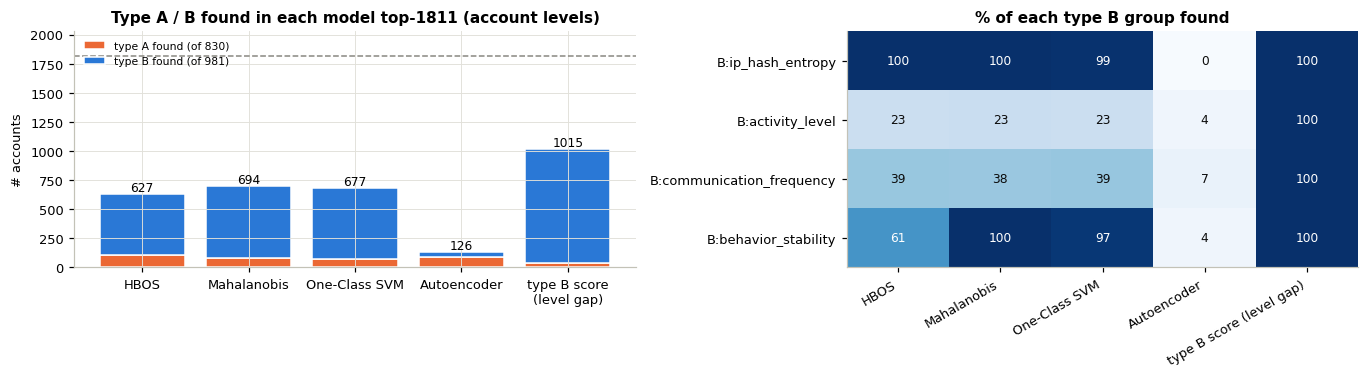

top-1811 of each model (account levels):
  HBOS                     type A  107 / 830 | type B  520 / 981 | neither 1184
  Mahalanobis              type A   78 / 830 | type B  616 / 981 | neither 1117
  One-Class SVM            type A   70 / 830 | type B  607 / 981 | neither 1134
  Autoencoder              type A   86 / 830 | type B   40 / 981 | neither 1685
  type B score (level gap) type A   34 / 830 | type B  981 / 981 | neither  796

# found per type B group:
                           HBOS  Mahalanobis  One-Class SVM  Autoencoder  type B score (level gap)
B:ip_hash_entropy           207          207            205            1                       207
B:activity_level             60           62             60           11                       265
B:communication_frequency   102          101            103           18                       263
B:behavior_stability        151          246            239           10                       246


In [ ]:
from sklearn.svm import OneClassSVM
from sklearn.neural_network import MLPRegressor

L = LVz.to_numpy()   # ระดับพฤติกรรมประจำตัว (standardized) จาก section 7

def hbos(F, bins=20, alpha=1e-4):
    # Histogram-based Outlier Score: sum ของ log(1 / ความสูง bin) ทุก feature (normalized histogram)
    sc = np.zeros(len(F))
    for j in range(F.shape[1]):
        v = F[:, j]
        h, e = np.histogram(v, bins=bins); h = h / h.sum()
        idx = np.clip(np.searchsorted(e, v, side='right') - 1, 0, bins - 1)
        sc += np.log(1 / (h[idx] + alpha))
    return sc

s_hbos = hbos(L, 20)
inv_all = np.linalg.pinv(np.cov(L.T))
dL = L - L.mean(axis=0)
s_mhd = np.einsum('ij,jk,ik->i', dL, inv_all, dL)                     # Mahalanobis distance^2
fit_idx = np.random.RandomState(SEED).choice(N, 8000, replace=False)  # OCSVM: fit บน subsample 8,000 แถว (เร็วขึ้น) แล้วให้ score ทุกแถว
s_ocsvm = -OneClassSVM(kernel='rbf', nu=0.07, gamma='scale').fit(L[fit_idx]).decision_function(L)
ae = MLPRegressor(hidden_layer_sizes=(16, 6, 16), max_iter=300, early_stopping=True, random_state=SEED).fit(L, L)
s_ae = np.abs(ae.predict(L) - L).mean(axis=1)                         # Autoencoder reconstruction error

lv_models = {'HBOS': s_hbos, 'Mahalanobis': s_mhd, 'One-Class SVM': s_ocsvm, 'Autoencoder': s_ae, 'type B score\n(level gap)': s_B}
gA = {k: int((topk(v, n_ab) & sus).sum()) for k, v in lv_models.items()}
gB = {k: int((topk(v, n_ab) & typeB).sum()) for k, v in lv_models.items()}
gB_grp = pd.DataFrame({k: {'B:' + g['feats'][0]: int((topk(v, n_ab) & g['mask']).sum()) for g in B.values()} for k, v in lv_models.items()})
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.5), gridspec_kw={'width_ratios': [1.1, 1]})
names = list(lv_models)
ax[0].bar(names, [gA[k] for k in names], color=C_ANOM, edgecolor='white', label='type A found (of %d)' % sus.sum())
ax[0].bar(names, [gB[k] for k in names], bottom=[gA[k] for k in names], color=C_NORMAL, edgecolor='white', label='type B found (of %d)' % typeB.sum())
for i, k in enumerate(names):
    ax[0].text(i, gA[k] + gB[k], str(gA[k] + gB[k]), ha='center', va='bottom', fontsize=8)
ax[0].axhline(n_ab, color=C_MUTED, ls='--', lw=1)
ax[0].set(title='Type A / B found in each model top-%d (account levels)' % n_ab, ylabel='# accounts', ylim=(0, n_ab * 1.12))
ax[0].legend(loc='upper left', fontsize=7)
pct = gB_grp.div(pd.Series({'B:' + g['feats'][0]: int(g['mask'].sum()) for g in B.values()}), axis=0) * 100
ax[1].imshow(pct.values, cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax[1].set(xticks=range(len(names)), xticklabels=[n.replace(chr(10), ' ') for n in names], yticks=range(len(pct)), yticklabels=pct.index, title='% of each type B group found')
ax[1].grid(False); plt.setp(ax[1].get_xticklabels(), rotation=30, ha='right')
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        ax[1].text(j, i, '%.0f' % pct.values[i, j], ha='center', va='center', fontsize=8, color='white' if pct.values[i, j] > 60 else '#0b0b0b')
plt.tight_layout(); plt.show()
print('top-%d of each model (account levels):' % n_ab)
for k in names:
    print('  %-24s type A %4d / %d | type B %4d / %d | neither %4d' % (k.replace(chr(10), ' '), gA[k], sus.sum(), gB[k], typeB.sum(), n_ab - gA[k] - gB[k]))
print('\n# found per type B group:'); print(gB_grp.rename(columns=lambda c: c.replace(chr(10), ' ')).to_string())

- **ดูอะไร:** ให้แต่ละวิธีเลือก 1,811 account ที่น่าสงสัยที่สุดจากระดับพฤติกรรมประจำตัว แล้วนับว่าเจอแบบ A / B กี่คน (ซ้าย) และเจอแต่ละกลุ่มย่อยของแบบ B กี่ % (ขวา)
- **เห็นอะไร:**
  - HBOS เจอ 627 (B 520) · Mahalanobis 694 (B 616) · One-Class SVM 677 (B 607) · Autoencoder 126 (B 40) เทียบกับ type B score ที่เจอ B ครบ 981 · ที่เหลือของ top-1,811 (1,100–1,700 คน) เป็นคนที่ไม่อยู่ทั้งแบบ A และ B
  - HBOS / Mahalanobis / OCSVM เจอ **กลุ่ม bot ครบ ≈ 100%** และ Mahalanobis / OCSVM เจอกลุ่ม behavior_stability ต่ำ 97–100% แต่เจอกลุ่ม activity_level ต่ำแค่ ≈ 23% และ communication_frequency ต่ำแค่ 38–39%
  - Autoencoder แทบไม่เจออะไร (bot 1 / 207) — พฤติกรรมไม่สัมพันธ์กัน (8.1) จึงไม่มีโครงสร้างให้ encoder ใช้ error จึงไม่ได้แยกกลุ่มเล็กออกมา
  - แบบ A แทบไม่มีวิธีไหนเห็น (70–107) เพราะระดับประจำตัว (median 4 ช่วง) ไม่ไหวตามช่วง 4
- **ผลต่องาน → ทำอะไร:** กลุ่มที่ผิดปกติ *หลายมิติหรือแรงมาก* (bot ที่ต่ำพร้อมกัน 3 feature, behavior_stability ต่ำมาก) วิธีมาตรฐานเห็นชัด = เป็น anomaly จริงไม่ใช่ artifact ของ `gap_split` · แต่กลุ่มที่ต่ำผิดปกติแค่มิติเดียวถูกอีก 30 มิติกลบ (เหมือน `IF on levels` ใน section 7) → ยังต้องใช้ type B score ที่ดูทีละ feature · ไม่มีวิธีไหนเจอกลุ่มใหม่ จึงไม่เปลี่ยน final score

### 8.3 นอกแบบ A/B ยังมี anomaly ซ่อนอยู่ไหม

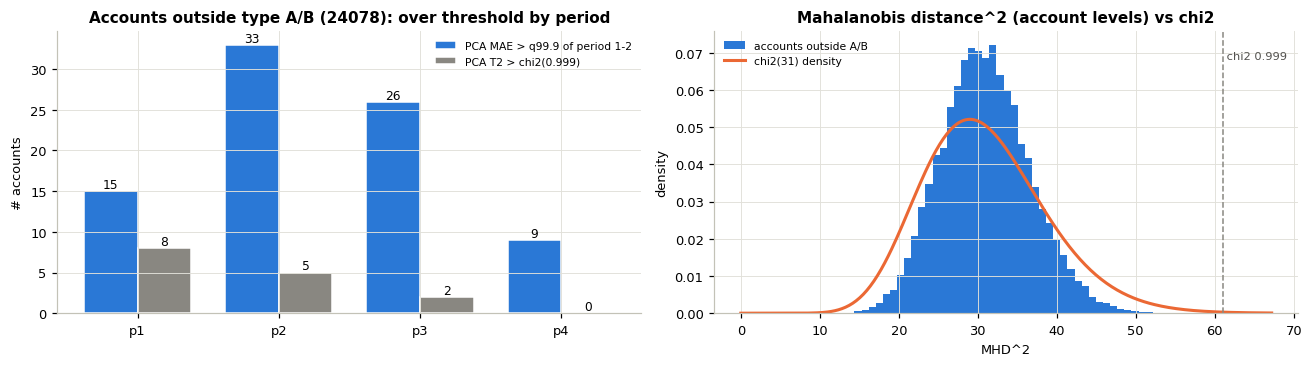

outside A/B: 24078 accounts
  PCA MAE > q99.9 by period : {'p1': 15, 'p2': 33, 'p3': 26, 'p4': 9}
  PCA T2 > chi2 by period   : {'p1': 8, 'p2': 5, 'p3': 2, 'p4': 0}
  MHD^2 > chi2(31, 0.999) = 61.1 : observed 1 | expected if normal 24.1
  MHD^2 mean: outside A/B 31.0 (chi2 mean = 31) | type B 59.3 | type A 33.4

overlap of top-1% (241) among accounts outside A/B (by chance = 2.4):
         PCA MAE  PCA T2  HBOS  MHD  OCSVM   AE
PCA MAE      241       0    10   33     31   44
PCA T2         0     241    23   30     26    8
HBOS          10      23   241   89     84   30
MHD           33      30    89  241    203   87
OCSVM         31      26    84  203    241   78
AE            44       8    30   87     78  241


In [ ]:
REST = ~AB
n_rest = int(REST.sum())
# (1) temporal: account ที่เหลือ เกินเกณฑ์ใน p3/p4 มากกว่า p1/p2 ไหม (ถ้ามี anomaly ซ่อน p3/p4 ต้องสูงกว่า)
THR_Q = np.quantile(np.concatenate([MAE[1], MAE[2]]), 0.999)
rest_mae = [int((REST & (MAE[p] > THR_Q)).sum()) for p in range(1, 5)]
rest_t2 = [int((REST & (T2[p] > THR_T2)).sum()) for p in range(1, 5)]
# (2) levels: ใช้ account ที่เหลือเป็น reference ของ "ปกติ" แล้วดูว่า MHD^2 เป็น chi2 ไหม (ถ้ามีกลุ่มซ่อน หางจะเกิน chi2)
mu_n = L[REST].mean(axis=0); inv_n = np.linalg.pinv(np.cov(L[REST].T))
dn = L - mu_n
md2_n = np.einsum('ij,jk,ik->i', dn, inv_n, dn)
DF = L.shape[1]
thr_md = stats.chi2.ppf(0.999, DF)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
w = 0.38
ax[0].bar(xs - w / 2, rest_mae, w, color=C_NORMAL, edgecolor='white', label='PCA MAE > q99.9 of period 1-2')
ax[0].bar(xs + w / 2, rest_t2, w, color=C_MUTED, edgecolor='white', label='PCA T2 > chi2(0.999)')
for x, a, b in zip(xs, rest_mae, rest_t2):
    ax[0].text(x - w / 2, a, str(a), ha='center', va='bottom', fontsize=8); ax[0].text(x + w / 2, b, str(b), ha='center', va='bottom', fontsize=8)
ax[0].set(title='Accounts outside type A/B (%d): over threshold by period' % n_rest, xticks=xs, xticklabels=['p1', 'p2', 'p3', 'p4'], ylabel='# accounts')
ax[0].legend(loc='upper right', fontsize=7)
grid = np.linspace(0, max(np.quantile(md2_n[REST], 0.9999), thr_md) * 1.1, 300)
ax[1].hist(md2_n[REST], bins=grid[::4], density=True, color=C_NORMAL, label='accounts outside A/B')
ax[1].plot(grid, stats.chi2.pdf(grid, DF), color=C_ANOM, lw=2, label='chi2(%d) density' % DF)
ax[1].axvline(thr_md, color=C_MUTED, ls='--', lw=1)
ax[1].text(thr_md, ax[1].get_ylim()[1] * 0.9, ' chi2 0.999', color='#52514e', fontsize=7.5)
ax[1].set(title='Mahalanobis distance^2 (account levels) vs chi2', xlabel='MHD^2', ylabel='density')
ax[1].legend(loc='upper left', fontsize=7)
plt.tight_layout(); plt.show()

print('outside A/B: %d accounts' % n_rest)
print('  PCA MAE > q99.9 by period :', dict(zip(['p1', 'p2', 'p3', 'p4'], rest_mae)))
print('  PCA T2 > chi2 by period   :', dict(zip(['p1', 'p2', 'p3', 'p4'], rest_t2)))
print('  MHD^2 > chi2(%d, 0.999) = %.1f : observed %d | expected if normal %.1f' % (DF, thr_md, int((REST & (md2_n > thr_md)).sum()), 0.001 * n_rest))
print('  MHD^2 mean: outside A/B %.1f (chi2 mean = %d) | type B %.1f | type A %.1f' % (md2_n[REST].mean(), DF, md2_n[typeB].mean(), md2_n[sus].mean()))
# (3) detector ต่างๆ เห็นพ้องกันไหมว่าใครใน account ที่เหลือน่าสงสัย (top 1% ของแต่ละตัว)
k1 = int(round(0.01 * n_rest))
det = {'PCA MAE': m34, 'PCA T2': np.maximum(T2[3], T2[4]), 'HBOS': s_hbos, 'MHD': s_mhd, 'OCSVM': s_ocsvm, 'AE': s_ae}
tops = {k: set(pd.Series(v)[REST].sort_values(ascending=False).index[:k1]) for k, v in det.items()}
print('\noverlap of top-1%% (%d) among accounts outside A/B (by chance = %.1f):' % (k1, k1 * k1 / n_rest))
print(pd.DataFrame([[len(tops[a] & tops[b]) for b in det] for a in det], index=list(det), columns=list(det)).to_string())

- **ดูอะไร:** เฉพาะ 24,078 account ที่ไม่อยู่ในแบบ A/B · (ซ้าย) จำนวนที่เกินเกณฑ์ PCA จาก 8.1 แยกตามช่วง — ถ้ามีการเปลี่ยนพฤติกรรมซ่อนอยู่ ช่วง 3/4 ต้องสูงกว่าช่วง 1/2 · (ขวา) Mahalanobis² เมื่อใช้คนกลุ่มนี้เป็น reference เทียบกับ χ²(31) — ถ้ามีกลุ่มผิดปกติซ่อน หางขวาจะยาวเกิน χ² · ตารางล่าง: top 1% ของแต่ละ detector ซ้อนกันกี่คน
- **เห็นอะไร:**
  - ซ้าย: MAE เกินเกณฑ์ p1 15 · p2 33 · p3 26 · p4 9 (T²: 8 · 5 · 2 · 0) → ช่วงหลัง *ไม่ได้มากกว่า* ช่วงอ้างอิง เป็นแค่ระดับ noise ของเกณฑ์ q99.9
  - ขวา: Mahalanobis² เฉลี่ย 31.0 เท่ากับค่าเฉลี่ยของ χ²(31) และหางสั้นกว่า χ² ด้วย (หางสั้นเพราะการเติม median ให้ช่องที่ missing ดึงค่าเข้าหาศูนย์กลาง) · เกิน χ² 0.999 = 61.1 แค่ **1 account** ทั้งที่ถ้าเป็นปกติล้วนคาดไว้ ≈ 24 · เทียบกับแบบ B ที่ Mahalanobis² เฉลี่ย 59.3
  - ตาราง: detector บนระดับพฤติกรรม (HBOS, MHD, OCSVM, AE) เลือกคนซ้ำกันเกินโอกาส (เช่น MHD กับ OCSVM 203 / 241) เพราะทุกตัววัด "ระยะจากศูนย์กลาง" ของ distribution เดียวกัน จึงเลือกคนที่อยู่ขอบของกลุ่มปกติเหมือนกัน แต่ขอบนี้ไม่เกิน χ² (กราฟขวา) จึงไม่ใช่กลุ่มผิดปกติ
- **ผลต่องาน → ทำอะไร:** นอกแบบ A/B ข้อมูลเป็นไปตามสมมติฐาน "คนปกติ" ของ Mahalanobis ทั้งในมุมเวลาและมุมระดับพฤติกรรม → **ไม่มีหลักฐานของ anomaly กลุ่มที่สาม** · คง final score เดิม · buffer ใน section 9 จึงเป็นการเผื่อตามธรรมชาติของ F3 ไม่ใช่เพราะเจอคนน่าสงสัยเพิ่ม

## 9. เลือก threshold

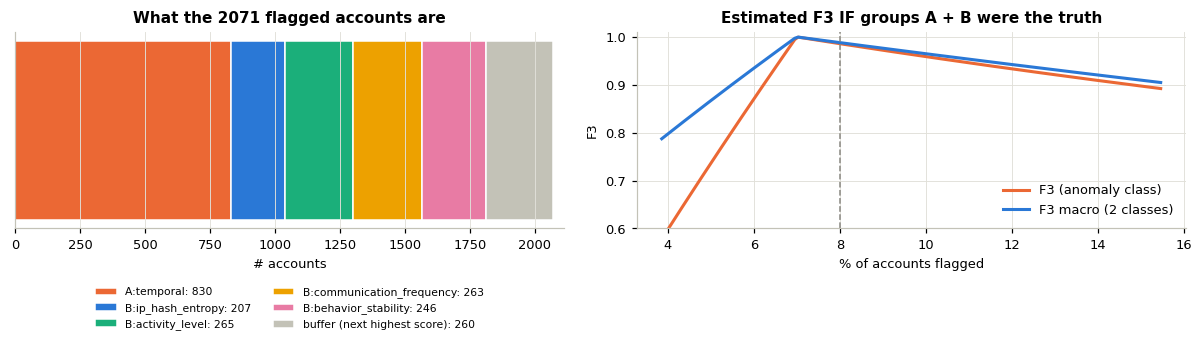

flag  5.0% (1300 rows): F3 = 0.739 | F3 macro = 0.868
flag  6.0% (1560 rows): F3 = 0.874 | F3 macro = 0.936
flag  7.0% (1820 rows): F3 = 1.000 | F3 macro = 1.000
flag  8.0% (2080 rows): F3 = 0.985 | F3 macro = 0.988
flag  9.0% (2340 rows): F3 = 0.972 | F3 macro = 0.976
flag 10.0% (2580 rows): F3 = 0.959 | F3 macro = 0.965
flag 12.0% (3100 rows): F3 = 0.934 | F3 macro = 0.943
chosen: K = 2071 (8.00%) | A + B covered: 1811 / 1811


In [ ]:
K_FINAL = int(round(0.08 * N))   # flag top 8% ของ final score

def fbeta(tp, fp, fn, beta=3):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return (1 + beta ** 2) * p * r / (beta ** 2 * p + r) if p + r else 0.0

ks = np.arange(1000, 4001, 20)
f_bin, f_mac = [], []
for k in ks:
    pr = topk(final, k)
    tp = int((pr & AB).sum()); fp = int(k - tp); fn = n_ab - tp; tn = N - tp - fp - fn
    f1 = fbeta(tp, fp, fn); f0 = fbeta(tn, fn, fp)
    f_bin.append(f1); f_mac.append((f1 + f0) / 2)

pr = topk(final, K_FINAL)
parts = {'A:temporal': int((pr & sus).sum())}
parts.update({'B:' + g['feats'][0]: int((pr & g['mask']).sum()) for g in B.values()})
parts['buffer (next highest score)'] = int((pr & ~AB).sum())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
left = 0
for i, (k, v) in enumerate(parts.items()):
    ax[0].barh([0], [v], left=left, color=PAL[(i + 1) % len(PAL)] if 'buffer' not in k else '#c3c2b7', edgecolor='white', label='%s: %d' % (k, v))
    left += v
ax[0].set(title='What the %d flagged accounts are' % K_FINAL, xlabel='# accounts', yticks=[], xlim=(0, K_FINAL * 1.02))
ax[0].legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)
ax[1].plot(ks / N * 100, f_bin, color=C_ANOM, lw=2, label='F3 (anomaly class)')
ax[1].plot(ks / N * 100, f_mac, color=C_NORMAL, lw=2, label='F3 macro (2 classes)')
ax[1].axvline(K_FINAL / N * 100, color=C_MUTED, ls='--', lw=1)
ax[1].set(title='Estimated F3 IF groups A + B were the truth', xlabel='% of accounts flagged', ylabel='F3', ylim=(0.6, 1.01))
ax[1].legend(loc='lower right'); plt.tight_layout(); plt.show()
for pct in (5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 12.0):
    i = int(np.argmin(np.abs(ks / N * 100 - pct)))
    print('flag %4.1f%% (%4d rows): F3 = %.3f | F3 macro = %.3f' % (pct, ks[i], f_bin[i], f_mac[i]))
print('chosen: K = %d (%.2f%%) | A + B covered: %d / %d' % (K_FINAL, K_FINAL / N * 100, int((pr & AB).sum()), n_ab))

- **ดูอะไร:** ใน account ที่ flag มีใครบ้าง (ซ้าย) และ F3 ที่ *ประมาณ* ได้ถ้าสมมติว่ากลุ่ม A + B คือคำตอบจริง ตามจำนวนที่ flag (ขวา) — ⚠️ เป็นการประมาณจากข้อมูลเอง **ไม่ได้ใช้ label**
- **เห็นอะไร:** F3 สูงสุดตรงที่ flag ≈ 7% (= ขนาด A + B) ถ้า flag *ขาด* F3 ร่วงชันมาก (5% → 0.74) ขณะที่ flag *เกิน* F3 ลดช้า (8% → 0.985, 10% → 0.96) เพราะ F3 ให้ recall หนักกว่า 9 เท่า
- **ผลต่องาน → ทำอะไร:** เลือก **flag 8% (2,071 account)**: ครอบแบบ A + B ครบ 1,811 คน และเผื่ออีก 260 account ที่ score สูงรองลงมา (เช่น เปลี่ยนแรงแต่ไม่ถึงเกณฑ์ หรืออยู่ใกล้จุดแบ่งของแบบ B) · section 8 ไม่พบ anomaly กลุ่มอื่นนอกแบบ A/B จึงไม่ flag มากกว่านี้ แต่ยังเผื่อไว้เพราะการพลาด anomaly แพงกว่าการ flag เกิน

## 10. Export

In [ ]:
pred = topk(final, K_FINAL).astype(int)
sub = pd.DataFrame({'id': ['ANS%05d' % i for i in range(1, N + 1)], 'task5': pred})   # ลำดับเดียวกับ test.csv ไม่ sort
assert len(sub) == N and sub['id'].is_unique and set(sub['task5'].unique()) <= {0, 1}
out = os.path.join(OUT_DIR, 'task5_pred.csv')
sub.to_csv(out, index=False)
print('saved:', out)
print('rows: %d | flagged: %d (%.2f%%)' % (len(sub), sub['task5'].sum(), sub['task5'].mean() * 100))
print(sub.head(3).to_string(index=False))

saved: /content/task5_pred.csv
rows: 25889 | flagged: 2071 (8.00%)
      id  task5
ANS00001      1
ANS00002      0
ANS00003      1


## สรุป

- **ข้อมูล:** missing ≈ 5% แบบสุ่ม + noise ทั้งไฟล์ → ใช้วิธีที่ robust และทนต่อ missing
- **Anomaly แบบ A (830 account):** พฤติกรรมเปลี่ยนกะทันหันหลายด้านพร้อมกันในช่วงหลัง (ย้ายที่ login ไกล, skill พุ่ง, ลบเพื่อน, โอน currency, ซื้อของถี่) + มักเปลี่ยนรหัสและขายของ → ลักษณะ account ถูกขโมย
- **Anomaly แบบ B (981 account):** ผิดปกติมาตั้งแต่แรกและคงที่ทุกช่วง เช่น กลุ่ม bot (IP เดิม เวลาเข้าเดิม เล่นนานเท่าเดิม) และกลุ่มที่ activity / communication / behavior stability ต่ำผิดปกติ → flag ของระบบเดิมมองไม่เห็นกลุ่มนี้
- **Feature engineering** ที่ตรงกับแต่ละแบบสำคัญกว่าการเลือก algorithm: IF baseline บนค่าดิบหาได้ไม่ถึงครึ่ง
- **ตรวจซ้ำด้วยวิธีมาตรฐาน (section 8):** PCA ที่ fit บนช่วง 1–2 เจอการเปลี่ยนในช่วง 4 เป็นแบบ A ทั้งหมด (741 / 741) · HBOS / Mahalanobis / One-Class SVM เห็นกลุ่ม bot และ behavior_stability ต่ำครบ แต่เห็นกลุ่มที่ต่ำแค่มิติเดียวไม่ถึงครึ่ง · account นอกแบบ A/B มี Mahalanobis² เป็นไปตาม χ² (เกิน 0.999 แค่ 1 account จากที่คาดไว้ ≈ 24) → ไม่มี anomaly กลุ่มอื่น
- **Threshold:** กลุ่มที่แยกชัดรวม 7.0% + เผื่อตามธรรมชาติของ F3 → flag 8%
- **Business impact:** ระบบที่ดูแค่ flag จะ flag คนปกติจำนวนมาก (เช่น `vpn_usage` = 1 มีเกือบ 3,900 account แต่ส่วนใหญ่เป็นคนปกติ) และพลาด bot ทั้งกลุ่ม · วิธีนี้ส่งรายชื่อให้ทีม security ตรวจ 2,071 account แยกตามประเภท (ขโมย / bot / อื่นๆ) และเรียงลำดับความเร่งด่วนตาม score ได้